# FloodGuard AI — Flood Risk Research Prototype

**A reproducible Google Colab demonstration using the official pretrained LarNO model (Latent Autoregressive Neural Operator).**

| Resource | Link |
|---|---|
| LarNO GitHub | https://github.com/holmescao/LarNO |
| Pretrained checkpoint | https://huggingface.co/holmescao/LarNO |
| Benchmark dataset | https://huggingface.co/datasets/holmescao/LarNO-dataset |
| Official Colab demo | https://colab.research.google.com/drive/1I9TDBCC0rQU3dKMujRCCm8hRMSumGe7E |
| Paper | Cao et al., *Journal of Hydrology* (2026), DOI: 10.1016/j.jhydrol.2026.135686 |

> **Research and education only.** This notebook is **not** a certified flood-warning system and produces **no emergency alerts**.

## A.1 — What is FloodGuard AI?

FloodGuard AI is a research prototype that runs **real, pretrained flood-depth prediction** on the official LarNO benchmark and reports honest, reproducible results:

1. It downloads the **official pretrained checkpoint** and the **official benchmark data** (Futian district, Shenzhen, China).
2. It runs the **official LarNO inference pipeline** (`test.py`) — we do not reimplement or substitute the model.
3. It visualizes the actual model outputs and evaluates them against the MIKE+ hydrodynamic reference.
4. It separates verified benchmark results from a clearly-labelled research plan for Egypt.

### A.2 — What is LarNO, in simple language?

Predicting urban flooding means forecasting **how deep water gets, everywhere, minute by minute**. Running a classical hydraulic solver (MIKE+) for a 100 km² city takes hours. LarNO instead *learns* the mapping from (rainfall, terrain) to water depth from many solver simulations:

- **Neural operator (FNO-based):** learns a function that maps rainfall + terrain fields to water-depth fields, at any grid resolution.
- **Latent autoregression (CGRU memory):** at each 5-minute step, the model carries a hidden "memory" of the previous flood state, so flooding evolves realistically over time.
- **Inputs:** 13 channels per step = 6 recent rainfall frames + 6 cumulative-rainfall frames + 1 static terrain (DEM) map. **Output:** a water-depth map (metres) for each 5-minute step.

On the released 20 m benchmark, LarNO reproduces the MIKE+ reference with millimetre-level mean errors while being orders of magnitude faster.

### A.3 — The dataset and its limitations

- **Futian (`region1_20m`)**: ~100 km² of Shenzhen, 400 × 560 grid at 20 m, 72 steps (6 h at 5-min steps) per event. 16 test events (`event65`–`event80` in the official list; `event79` is absent from the HuggingFace mirror — the notebook detects this automatically).
- Ground-truth water depth comes from **MIKE+ simulations**, not from observed floods.
- The **drainage network is confidential** and not released — the model works without it, but this limits physical completeness.
- The released data is a **20 m downsample** of the paper's 5 m setup, so numbers here will differ from the paper's headline table.

### A.4 — What this is *not*

- It is **not** a validated real-world flood forecast. Metrics are computed against a **simulated reference** on a **Chinese urban catchment**.
- It says **nothing** about accuracy in Egypt (see Part 2). The checkpoint has never been trained or validated on Egyptian terrain, rainfall or observations.

---
# Section B — Runtime & Hardware Check

Detects Google Colab, Python/PyTorch/CUDA versions, GPU model and free VRAM, and warns (without failing) on CPU-only runtimes.

In [1]:
import os, sys, platform

IS_COLAB = False
try:
    import google.colab  # noqa: F401
    IS_COLAB = True
except ImportError:
    pass

print("=" * 64)
print("FloodGuard AI - Environment Report")
print("=" * 64)
print(f"Running in Google Colab   : {IS_COLAB}")
print(f"Python                    : {sys.version.split()[0]}")
print(f"Operating system          : {platform.system()} {platform.release()}")

try:
    import torch
except ImportError:
    torch = None
    print("PyTorch                   : NOT INSTALLED (will be installed in Section C)")

DEVICE = "cpu"
CPU_ONLY = True
if torch is not None:
    print(f"PyTorch                   : {torch.__version__}")
    print(f"CUDA available (torch)    : {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        print(f"CUDA version              : {torch.version.cuda}")
        props = torch.cuda.get_device_properties(0)
        free_b, total_b = torch.cuda.mem_get_info(0)
        print(f"GPU                       : {props.name}")
        print(f"GPU memory total / free   : {total_b/1e9:.1f} GB / {free_b/1e9:.1f} GB")
        DEVICE = "0"
        CPU_ONLY = False
        if free_b < 3e9:
            print("[warning] Less than 3 GB of VRAM is free. Another process may be using the GPU.")
            print("          If inference fails with CUDA out-of-memory, restart the runtime.")
    else:
        print("Execution device          : CPU only")
        print("[warning] No GPU detected. One 6-hour event (72 autoregressive steps on a 400x560 grid)")
        print("          can take tens of minutes on CPU. Strongly recommended:")
        print("          Runtime -> Change runtime type -> T4 GPU.")
print("=" * 64)
print(f"-> Inference will use device flag: --device {DEVICE}")

FloodGuard AI - Environment Report
Running in Google Colab   : True
Python                    : 3.13.15
Operating system          : Linux 6.6.122+


PyTorch                   : 2.11.0+cu130
CUDA available (torch)    : True
CUDA version              : 13.0


GPU                       : Tesla T4
GPU memory total / free   : 15.6 GB / 13.5 GB
-> Inference will use device flag: --device 0


---
# Section C — Install Dependencies (official repository)

We clone the official repository and install it exactly the way the official Colab demo documents it:
`pip install -e . --no-deps` followed by the dependency list from the demo, including the pinned
`torch-harmonics==0.7.3` (required at import time).

We do **not** upgrade Colab's NumPy/PyTorch — the notebooks keeps the runtime's own versions.

In [2]:
import subprocess, sys, os, importlib

LARNO_DIR  = "/content/LarNO"                       # official repository
PKG_DIR    = f"{LARNO_DIR}/code/urbanflood_larfno"  # installable package
PROJECT_DIR = "/content/FloodGuard_AI"              # our working/results folder
sys.path.insert(0, PKG_DIR)

os.makedirs(PROJECT_DIR, exist_ok=True)

# 1) Clone the official repository (shallow) if it is not present yet.
if not os.path.isdir(os.path.join(LARNO_DIR, ".git")):
    print("Cloning https://github.com/holmescao/LarNO ...")
    r = subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/holmescao/LarNO", LARNO_DIR],
                       capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError("git clone failed:\n" + r.stderr[-2000:])
else:
    print("LarNO repository already present.")

def pip_install(args, label):
    cmd = [sys.executable, "-m", "pip", "install", "-q"] + args
    r = subprocess.run(cmd, capture_output=True, text=True, cwd=PKG_DIR)
    if r.returncode != 0:
        print(f"[FAILED] {label}")
        print(r.stdout[-2000:])
        print(r.stderr[-2000:])
        raise RuntimeError(f"pip install failed: {label}")
    print(f"[ok] {label}")

# 2) Install the official package + the official demo dependency list.
pip_install(["-e", ".", "--no-deps"], "LarNO local package (editable)")
pip_install(["tensorly", "tensorly-torch", "torch-harmonics==0.7.3",
             "ruamel.yaml", "configmypy", "opt-einsum", "h5py", "zarr",
             "matplotlib", "numpy>=1.25", "pandas", "tqdm", "scipy",
             "opencv-python", "openpyxl", "torchmetrics"],
            "runtime dependencies (official Colab demo list)")

# 3) Verify that the model code imports.
try:
    import neuralop
    print("[ok] neuralop import verified (version", neuralop.__version__ + ")")
except Exception as e:
    print("[FAILED] neuralop import:", repr(e))
    raise

# 4) Print the verified dependency versions used by this run.
import importlib.metadata as md
print("\nVerified dependency versions:")
for pkg in ["neuraloperator", "torch", "torch-harmonics", "tensorly",
            "tensorly-torch", "configmypy", "numpy", "pandas", "scipy",
            "matplotlib", "openpyxl", "huggingface-hub"]:
    try:
        print(f"  {pkg:18s} {md.version(pkg)}")
    except Exception:
        pass

LarNO repository already present.


[ok] LarNO local package (editable)


[ok] runtime dependencies (official Colab demo list)


[ok] neuralop import verified (version 1.0.1)

Verified dependency versions:
  neuraloperator     1.0.1
  torch              2.11.0+cu130
  torch-harmonics    0.7.3
  tensorly           0.10.0
  tensorly-torch     0.5.0
  configmypy         0.2.0
  numpy              2.1.3
  pandas             2.2.3
  scipy              1.16.3
  matplotlib         3.10.0
  openpyxl           3.1.5
  huggingface-hub    1.33.0


---
# Section D — Obtain the Official Pretrained Checkpoint

Downloaded from the official model repository [holmescao/LarNO](https://huggingface.co/holmescao/LarNO)
(`exp_weights.zip`, ~108 MB) using `huggingface_hub` — the documented HuggingFace mirror of the official weights.

The archive contains `exp/<expr_id>/weights/<checkpoint_name>/<checkpoint_name>_state_dict.pt`,
which is exactly where the official code expects it. We extract it and **verify it exists and is non-empty**
before continuing.

In [3]:
import os, glob, re, zipfile
from huggingface_hub import snapshot_download

MODEL_REPO_ID  = "holmescao/LarNO"
WEIGHTS_ZIP    = "exp_weights.zip"
MODEL_SRC_DIR  = "/content/LarNO/model_src"
EXP_ROOT       = "/content/LarNO/exp"

os.makedirs(MODEL_SRC_DIR, exist_ok=True)
zip_path = os.path.join(MODEL_SRC_DIR, WEIGHTS_ZIP)

if not (os.path.exists(zip_path) and os.path.getsize(zip_path) > 0):
    print("Downloading pretrained weights from HuggingFace (holmescao/LarNO) ...")
    snapshot_download(repo_id=MODEL_REPO_ID, allow_patterns=[WEIGHTS_ZIP],
                      local_dir=MODEL_SRC_DIR)
else:
    print("Weights archive already present (skipping download).")

assert os.path.exists(zip_path) and os.path.getsize(zip_path) > 0, \
    "Checkpoint archive is missing or empty - download failed."
print(f"Checkpoint archive: {zip_path}  ({os.path.getsize(zip_path)/1e6:.1f} MB)")

def find_checkpoints():
    paths = glob.glob(os.path.join(EXP_ROOT, "**", "*_state_dict.pt"), recursive=True)
    def epoch_of(p):
        m = re.search(r"model_epoch_(\d+)", os.path.basename(p))
        return int(m.group(1)) if m else -1
    return sorted(paths, key=epoch_of)

checkpoints = find_checkpoints()
if not checkpoints:
    print("Extracting checkpoint archive ...")
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall("/content/LarNO")
    checkpoints = find_checkpoints()

assert checkpoints, "No *_state_dict.pt found after extracting the archive."
CHECKPOINT_PATH = checkpoints[-1]                      # highest epoch
EXP_ID = CHECKPOINT_PATH.split(os.sep + "exp" + os.sep, 1)[1].split(os.sep)[0]
CKPT_NAME = os.path.basename(os.path.dirname(CHECKPOINT_PATH))

print(f"Experiment id   : {EXP_ID}")
print(f"Checkpoint      : {CKPT_NAME}")
print(f"State dict file : {CHECKPOINT_PATH}")
print(f"File size       : {os.path.getsize(CHECKPOINT_PATH)/1e6:.1f} MB")

Weights archive already present (skipping download).
Checkpoint archive: /content/LarNO/model_src/exp_weights.zip  (107.9 MB)
Experiment id   : 20260220_183648_006352
Checkpoint      : model_epoch_992_error@0.000055821
State dict file : /content/LarNO/exp/20260220_183648_006352/weights/model_epoch_992_error@0.000055821/model_epoch_992_error@0.000055821_state_dict.pt
File size       : 116.4 MB


In [4]:
# Verify the checkpoint is loadable and matches the documented architecture
import torch, re, os

CFG_HIDDEN, CFG_NMODES_H, CFG_NMODES_W, CFG_NLAYERS = 32, 100, 140, 4

state_dict = torch.load(CHECKPOINT_PATH, map_location="cpu")
n_tensors = len(state_dict)
n_params  = sum(v.numel() for v in state_dict.values() if hasattr(v, "numel"))
has_module_prefix = any(k.startswith("module.") for k in state_dict)
conv0 = state_dict.get("module.fno_blocks.convs.0.weight.tensor")
conv_shape = tuple(conv0.shape) if conv0 is not None else None

print(f"Tensors in checkpoint   : {n_tensors}")
print(f"Total parameters        : {n_params/1e6:.1f} M")
print(f"DataParallel 'module.'  : {has_module_prefix} (the official test.py strips this prefix)")
print(f"Spectral conv weight    : {conv_shape}  (expected hidden={CFG_HIDDEN}, modes={CFG_NMODES_H}x{CFG_NMODES_W//2+1})")

ok = (conv_shape is not None
      and conv_shape[0] == CFG_HIDDEN and conv_shape[1] == CFG_HIDDEN
      and conv_shape[2] == CFG_NMODES_H and conv_shape[3] == CFG_NMODES_W // 2 + 1)
assert ok, "Checkpoint architecture does not match the documented config - do not continue."
print("[ok] Checkpoint architecture matches the documented LarNO configuration.")

Tensors in checkpoint   : 72
Total parameters        : 29.1 M
DataParallel 'module.'  : True (the official test.py strips this prefix)
Spectral conv weight    : (32, 32, 100, 71)  (expected hidden=32, modes=100x71)
[ok] Checkpoint architecture matches the documented LarNO configuration.


---
# Section E — Obtain the Benchmark Dataset (Futian Shenzhen, `region1_20m`)

We use the **officially supported LarNO benchmark** on HuggingFace
([holmescao/LarNO-dataset](https://huggingface.co/datasets/holmescao/LarNO-dataset)), the mirror documented by the project.

Per event, the dataset stores:

| File | Shape | Unit | Meaning |
|---|---|---|---|
| `rainfall.npy` | (72, 400, 560) | mm / 5 min | rainfall forcing |
| `h.npy` | (72, 400, 560) | metres | MIKE+ reference water depth |
| `geodata/region1_20m/dem.npy` | (400, 560) | metres | static terrain (`NaN` = buildings) |

**Storage note:** each event is ~258 MB (float64), so the 16-event test set is ~4.1 GB and the full
HuggingFace dataset repo is ~28.6 GB (there is also a 2.3 GB `benchmark.zip` mirror). To keep this
notebook fast and Colab-friendly we download **only the terrain plus `N_EVENTS` test events** (default 2),
directly from the dataset repository. Raise `N_EVENTS` for a larger evaluation; all events are official data.

In [5]:
import os, re, json
import numpy as np
from huggingface_hub import HfApi, snapshot_download

DATA_REPO_ID = "holmescao/LarNO-dataset"
DATA_ROOT    = "/content/LarNO/benchmark/urbanflood"
N_EVENTS     = 2   # official test events to download & evaluate (2 keeps runtime low; try 4-16)

api = HfApi()
entries = api.list_repo_tree(DATA_REPO_ID, path_in_repo="flood/region1_20m", repo_type="dataset")
available = {os.path.basename(f.path) for f in entries if f.path.rstrip("/") != "flood/region1_20m"}

official_test = [f"event{i}" for i in range(65, 81)]          # official configs/region1_test.txt
usable = [e for e in official_test if e in available]
missing = [e for e in official_test if e not in available]

print(f"Official test list (configs/region1_test.txt) : {len(official_test)} events")
print(f"Present in HuggingFace dataset mirror         : {len(usable)} events")
if missing:
    print(f"Note: {missing} is/are listed officially but absent from the HF mirror (upload omission).")
assert usable, "No test events available on the mirror - cannot continue."

CHOSEN_EVENTS = usable[:N_EVENTS]
print(f"Selected for this run: {CHOSEN_EVENTS}")

patterns = ["geodata/region1_20m/dem.npy"] + [f"flood/region1_20m/{e}/*" for e in CHOSEN_EVENTS]
print("Downloading dataset subset (skip-if-cached) ...")
snapshot_download(repo_id=DATA_REPO_ID, repo_type="dataset",
                  allow_patterns=patterns, local_dir=DATA_ROOT)
print("Dataset subset ready.")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Official test list (configs/region1_test.txt) : 16 events
Present in HuggingFace dataset mirror         : 15 events
Note: ['event79'] is/are listed officially but absent from the HF mirror (upload omission).
Selected for this run: ['event65', 'event66']


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Dataset subset ready.


In [6]:
# Verify files, shapes, dtypes, units and report storage use
import os
import numpy as np

dem_path = f"{DATA_ROOT}/geodata/region1_20m/dem.npy"
assert os.path.exists(dem_path), "DEM not found - dataset download incomplete."
dem = np.load(dem_path)
valid = dem[~np.isnan(dem)]
print(f"DEM   : shape={dem.shape} dtype={dem.dtype} "
      f"elevation range={valid.min():.2f}-{valid.max():.2f} m  NaN cells={int(np.isnan(dem).sum())}")

total_bytes = os.path.getsize(dem_path)
for ev in CHOSEN_EVENTS:
    rain = np.load(f"{DATA_ROOT}/flood/region1_20m/{ev}/rainfall.npy")
    h    = np.load(f"{DATA_ROOT}/flood/region1_20m/{ev}/h.npy")
    total_bytes += os.path.getsize(f"{DATA_ROOT}/flood/region1_20m/{ev}/rainfall.npy")
    total_bytes += os.path.getsize(f"{DATA_ROOT}/flood/region1_20m/{ev}/h.npy")
    print(f"{ev}: rainfall {rain.shape} {rain.dtype} (max {rain.max():.2f} mm/5min) | "
          f"h {h.shape} {h.dtype} (max {h.max():.2f} m)")
    assert rain.shape == (72, 400, 560) and h.shape == (72, 400, 560), f"Unexpected shape for {ev}"
    assert np.isfinite(rain).all() and np.isfinite(h).all(), f"Non-finite values in {ev}"

print(f"\nDownloaded dataset subset: {total_bytes/1e6:.1f} MB")

# Register the evaluated events as a subset test list (official region1_test.txt stays untouched).
subset_list_path = os.path.join(PKG_DIR, "configs", "region1_test_subset.txt")
with open(subset_list_path, "w") as f:
    f.write("\n".join(CHOSEN_EVENTS) + "\n")
print(f"Subset test list written: {subset_list_path}")

DEM   : shape=(400, 560) dtype=float32 elevation range=0.69-50.00 m  NaN cells=0


event65: rainfall (72, 400, 560) float64 (max 3.28 mm/5min) | h (72, 400, 560) float64 (max 2.20 m)


event66: rainfall (72, 400, 560) float64 (max 2.90 mm/5min) | h (72, 400, 560) float64 (max 2.23 m)

Downloaded dataset subset: 517.0 MB
Subset test list written: /content/LarNO/code/urbanflood_larfno/configs/region1_test_subset.txt


---
# Section F — Run the Official LarNO Inference Pipeline

We call the official `test.py` with the official `urbanflood_config_2d.yaml`. The config already points to the
pretrained architecture (`hidden_channels=32`, `n_modes=100x140`, `n_layers=4`); we first validate it, then run
inference on GPU (or CPU with a warning) and verify that **real output files** were produced.

Inference is deterministic: `model.eval()` with no dropout, `batch_size=1`, `shuffle=False`, and a fixed data
order — no random seeds are involved in prediction.

In [7]:
# Validate the official config against the checkpoint before running
import os, yaml, sys

CONFIG_PATH = os.path.join(PKG_DIR, "configs", "urbanflood_config_2d.yaml")
with open(CONFIG_PATH) as f:
    cfg_raw = yaml.safe_load(f)
cfg = cfg_raw.get("default", cfg_raw)

checks = {
    "tfno2d.hidden_channels": (cfg["tfno2d"]["hidden_channels"], 32),
    "tfno2d.n_modes_height":  (cfg["tfno2d"]["n_modes_height"], 100),
    "tfno2d.n_modes_width":   (cfg["tfno2d"]["n_modes_width"], 140),
    "tfno2d.n_layers":        (cfg["tfno2d"]["n_layers"], 4),
    "tfno2d.data_channels":   (cfg["tfno2d"]["data_channels"], 13),
    "eval.flood_threshold":   (cfg["eval"]["flood_threshold"], 0.03),
}
print("Config vs pretrained checkpoint:")
for key, (found, expected) in checks.items():
    status = "OK " if found == expected else "MISMATCH"
    print(f"  [{status}] {key:24s} found={found} expected={expected}")
    assert found == expected, f"Config mismatch: {key}"

print(f"  [OK ] test_list      : {cfg['data']['test_list']} (we override with region1_test_subset.txt)")
print(f"  [OK ] train_location : {cfg['data']['train_location']}")
print(f"  [OK ] eval location  : {cfg['eval']['locations']}")
print("\nConfig validated.")

Config vs pretrained checkpoint:
  [OK ] tfno2d.hidden_channels   found=32 expected=32
  [OK ] tfno2d.n_modes_height    found=100 expected=100
  [OK ] tfno2d.n_modes_width     found=140 expected=140
  [OK ] tfno2d.n_layers          found=4 expected=4
  [OK ] tfno2d.data_channels     found=13 expected=13
  [OK ] eval.flood_threshold     found=0.03 expected=0.03
  [OK ] test_list      : region1_test.txt (we override with region1_test_subset.txt)
  [OK ] train_location : region1_20m
  [OK ] eval location  : region1_20m

Config validated.


In [8]:
# Run official inference: python test.py --config ... (streams to console, logs to file)
import subprocess, sys, os, time, glob

RESULTS_LOG_DIR = f"{PROJECT_DIR}/results/logs"
os.makedirs(RESULTS_LOG_DIR, exist_ok=True)
RUN_LOG = f"{RESULTS_LOG_DIR}/larno_test_run.log"

cmd = [sys.executable, "test.py",
       "--config", "urbanflood_config_2d.yaml",
       "--expr_id", EXP_ID,
       "--data_root", DATA_ROOT,
       "--exp_root", EXP_ROOT,
       "--device", DEVICE,
       "--data.test_list", "region1_test_subset.txt"]

print("Running:", " ".join(cmd))
print(f"Events: {CHOSEN_EVENTS} | device flag: {DEVICE} | this takes ~30-60 s per event on a T4 GPU\n")

t0 = time.time()
proc = subprocess.run(cmd, cwd=PKG_DIR, capture_output=True, text=True)
elapsed = time.time() - t0

with open(RUN_LOG, "w") as f:
    f.write(" ".join(cmd) + "\n\n" + proc.stdout + "\n--- STDERR ---\n" + proc.stderr)

tail = "\n".join(proc.stdout.strip().splitlines()[-25:])
print(tail)
if proc.returncode != 0:
    print("\n--- STDERR (last 1500 chars) ---")
    print(proc.stderr[-1500:])
    raise RuntimeError(f"Official test.py failed with exit code {proc.returncode}. Full log: {RUN_LOG}")

print(f"\nOfficial inference finished in {elapsed:.1f} s (log: {RUN_LOG})")

# ---- verify the official pipeline produced real files -----------------
OUT_DIR        = os.path.join(EXP_ROOT, EXP_ID)
METRICS_XLSX   = sorted(glob.glob(f"{OUT_DIR}/test_metrics/region1_20m/*.xlsx"))
PRED_NPYS      = sorted(glob.glob(f"{OUT_DIR}/pred_results/region1_20m/**/*.npy", recursive=True))
VIS_GIFS       = sorted(glob.glob(f"{OUT_DIR}/visualization/region1_20m/**/*.gif", recursive=True))
VIS_PNGS       = sorted(glob.glob(f"{OUT_DIR}/visualization/region1_20m/**/*.png", recursive=True))

print(f"\nOfficial outputs: {len(METRICS_XLSX)} metrics xlsx | {len(PRED_NPYS)} prediction npy | "
      f"{len(VIS_GIFS)} GIF | {len(VIS_PNGS)} PNG")
assert METRICS_XLSX, "No metrics file produced - inference did not complete."
assert PRED_NPYS, "No prediction arrays produced."
assert len(PRED_NPYS) == len(CHOSEN_EVENTS), "Number of predictions does not match the number of events."

import numpy as np
pred0 = np.load(PRED_NPYS[0])
assert pred0.size > 0 and np.isfinite(pred0).all(), "Prediction array is empty or contains non-finite values."
print(f"[ok] Prediction array (first event): shape={pred0.shape} dtype={pred0.dtype} "
      f"range={pred0.min():.3f} .. {pred0.max():.3f} m")

Running: /usr/bin/python3 test.py --config urbanflood_config_2d.yaml --expr_id 20260220_183648_006352 --data_root /content/LarNO/benchmark/urbanflood --exp_root /content/LarNO/exp --device 0 --data.test_list region1_test_subset.txt
Events: ['event65', 'event66'] | device flag: 0 | this takes ~30-60 s per event on a T4 GPU



Testing experiment: 20260220_183648_006352
Loading checkpoint: /content/LarNO/exp/20260220_183648_006352/weights/model_epoch_992_error@0.000055821/model_epoch_992_error@0.000055821_state_dict.pt  (epoch=992)
Loaded Dynamic2DFlood test with 2 samples (location:region1_20m, locations:1, events:2)
Processing test sample 0, event_name: event65
Prediction time for sample 0: 10.136321783 seconds
{'event65': {'R2': 0.9936076275923019, 'MSE': 1.696483143823698e-05, 'RMSE': 0.004118838724475259, 'MAE': 0.001987642771181494, 'PeakR2': 0.9863460047634967, 'CSI': 0.8463332653045654}}
Saved visualization to /content/LarNO/exp/20260220_183648_006352/visualization/region1_20m/epoch_992/visualization_epoch_992_sample_event65.png
Saved comparison GIF to /content/LarNO/exp/20260220_183648_006352/visualization/region1_20m/epoch_992/event65_epoch992.gif
Processing test sample 1, event_name: event66
Prediction time for sample 1: 9.529647827 seconds
{'event65': {'R2': 0.9936076275923019, 'MSE': 1.6964831438

[ok] Prediction array (first event): shape=(400, 560, 72) dtype=float32 range=-0.023 .. 2.188 m


---
# Section G — Visualize the Actual Model Outputs

All figures below are computed from **real inference outputs** (no synthetic data).

Conventions used throughout:
- Water depth is shown in **metres**; the rainfall forcing in **mm / 5 min**.
- Terrain cells flagged as buildings/terrain walls (`DEM >= 50 m`, and `NaN` cells if present) are masked in maps.
- The **peak timestep `t*`** is defined exactly as in the official evaluation: the frame where the
  spatially-averaged *reference* depth is highest.
- The model can output slightly negative depths (no ReLU); display is floored at 0 for maps, and this is
  noted as a limitation — the official metrics use the raw values.

In [9]:
# Prepare shared arrays for the first evaluated event + plotting helpers
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from PIL import Image

EVENT = CHOSEN_EVENTS[0]
EV_PATH = f"{DATA_ROOT}/flood/region1_20m/{EVENT}"
FIG_DIR = f"{PROJECT_DIR}/results/figures"
os.makedirs(FIG_DIR, exist_ok=True)

rainfall = np.load(f"{EV_PATH}/rainfall.npy")          # (T,H,W) mm/5min
gt_depth = np.load(f"{EV_PATH}/h.npy")                 # (T,H,W) metres
dem      = np.load(dem_path)                           # (H,W) metres
pred_npy = [p for p in PRED_NPYS if EVENT in os.path.basename(p)][0]
pred_depth = np.load(pred_npy)                         # (H,W,T) metres (official layout)

# Official arrays: h is (T,H,W); predictions are (H,W,T) -> transpose GT to match
gt_hwt = np.transpose(gt_depth, (1, 2, 0))             # (H,W,T)

T = gt_hwt.shape[-1]
H, W = dem.shape
time_hours = np.arange(T) * 5.0 / 60.0

# Peak timestep t* (matches official PeakR2 definition: argmax of spatially-averaged TRUE depth)
t_star = int(np.argmax(gt_hwt.mean(axis=(0, 1))))

# Masks: invalid terrain = NaN or buildings (DEM at/above the official wall_height = 50 m)
invalid_terrain = np.isnan(dem) | (dem >= 50.0)
dem_masked = np.ma.masked_array(dem, mask=invalid_terrain)

def masked_depth(field2d, floor_at_zero=False):
    f = np.clip(field2d, 0, None) if floor_at_zero else field2d
    return np.ma.masked_array(f, mask=invalid_terrain)

print(f"Event {EVENT}: rainfall{rainfall.shape} gt{gt_hwt.shape} pred{pred_depth.shape} dem{dem.shape}")
print(f"Peak timestep t* = {t_star} ({(t_star*5)} min) | invalid/building terrain cells: {int(invalid_terrain.sum())}")
print(f"Depth ranges: GT 0..{gt_hwt.max():.2f} m | Pred {pred_depth.min():.3f}..{pred_depth.max():.2f} m "
      f"(model minimum is slightly negative: no non-negativity constraint, as in the official model)")

Event event65: rainfall(72, 400, 560) gt(400, 560, 72) pred(400, 560, 72) dem(400, 560)
Peak timestep t* = 12 (60 min) | invalid/building terrain cells: 118430
Depth ranges: GT 0..2.20 m | Pred -0.023..2.19 m (model minimum is slightly negative: no non-negativity constraint, as in the official model)


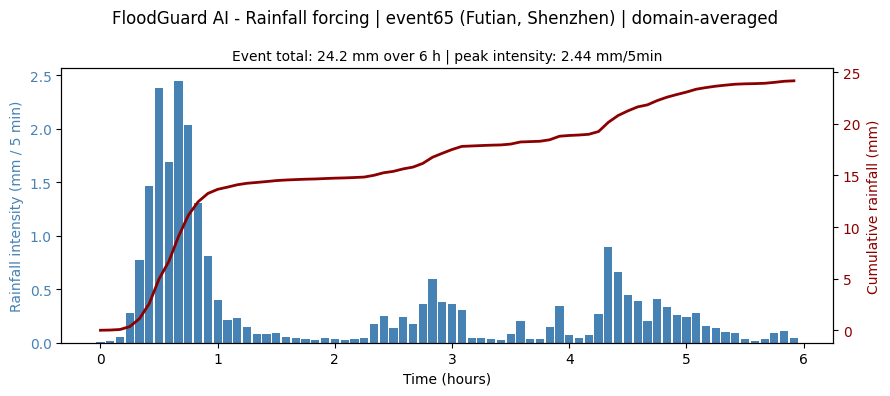

In [10]:
# Figure 1 - Input rainfall over time (hyetograph + cumulative, domain-average)
mean_intensity = rainfall.mean(axis=(1, 2))            # mm per 5-min step
rain_total_mm = mean_intensity.sum()                   # each step already represents 5 min

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.bar(time_hours, mean_intensity, width=0.07, color="steelblue", label="Mean intensity (mm / 5 min)")
ax1.set_xlabel("Time (hours)")
ax1.set_ylabel("Rainfall intensity (mm / 5 min)", color="steelblue")
ax1.tick_params(axis="y", labelcolor="steelblue")

ax2 = ax1.twinx()
ax2.plot(time_hours, np.cumsum(mean_intensity), color="darkred", lw=2, label="Cumulative depth (mm)")
ax2.set_ylabel("Cumulative rainfall (mm)", color="darkred")
ax2.tick_params(axis="y", labelcolor="darkred")

fig.suptitle(f"FloodGuard AI - Rainfall forcing | {EVENT} (Futian, Shenzhen) | domain-averaged")
ax1.set_title(f"Event total: {rain_total_mm:.1f} mm over 6 h | peak intensity: {mean_intensity.max():.2f} mm/5min",
              fontsize=10)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig1_rainfall_hyetograph_{EVENT}.png", dpi=150)
plt.show()

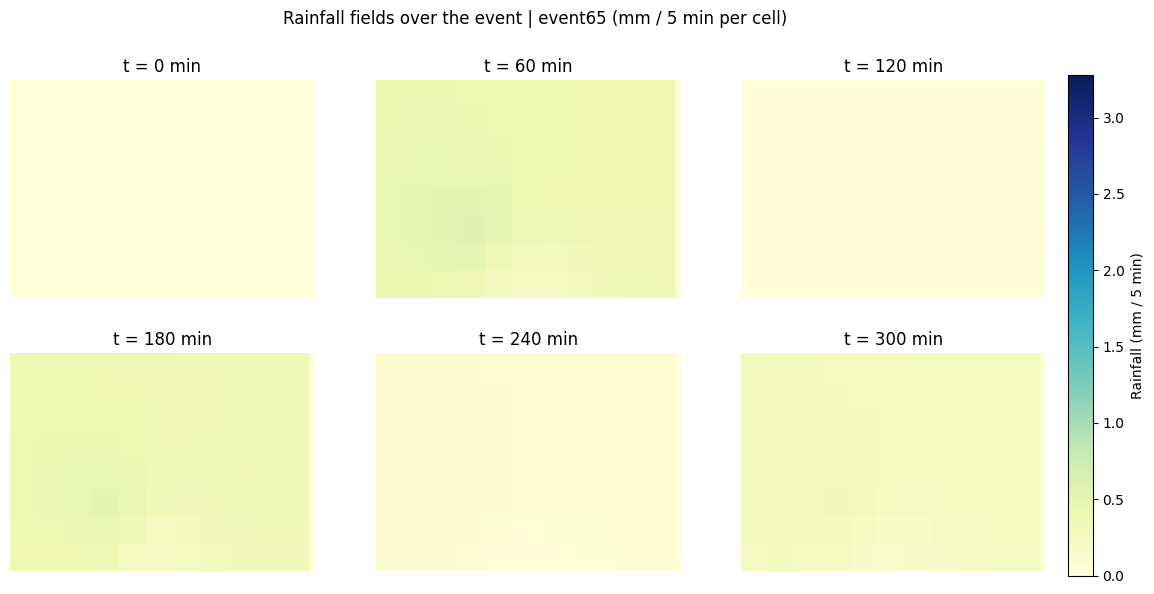

In [11]:
# Figure 2 - Rainfall snapshots across the event (real forcing fields)
snap_steps = [0, 12, 24, 36, 48, 60]
vmax_r = rainfall.max()
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, t in zip(axes.flat, snap_steps):
    im = ax.imshow(rainfall[t], cmap="YlGnBu", vmin=0, vmax=vmax_r)
    ax.set_title(f"t = {t*5} min")
    ax.axis("off")
fig.suptitle(f"Rainfall fields over the event | {EVENT} (mm / 5 min per cell)")
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, label="Rainfall (mm / 5 min)")
fig.savefig(f"{FIG_DIR}/fig2_rainfall_snapshots_{EVENT}.png", dpi=150, bbox_inches="tight")
plt.show()

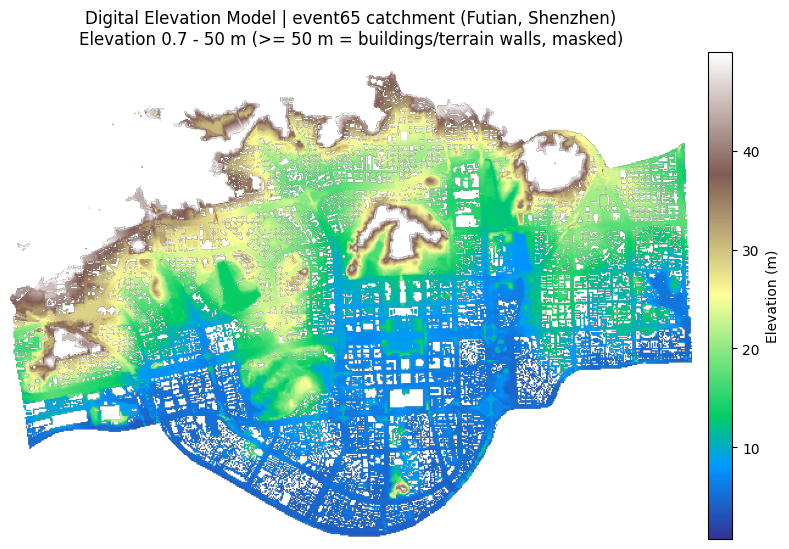

In [12]:
# Figure 3 - Digital Elevation Model (static terrain input)
fig, ax = plt.subplots(figsize=(9, 5.6))
im = ax.imshow(dem_masked, cmap="terrain")
ax.set_title(f"Digital Elevation Model | {EVENT} catchment (Futian, Shenzhen)\n"
             f"Elevation {np.nanmin(dem):.1f} - 50 m (>= 50 m = buildings/terrain walls, masked)")
ax.axis("off")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="Elevation (m)")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig3_dem.png", dpi=150)
plt.show()

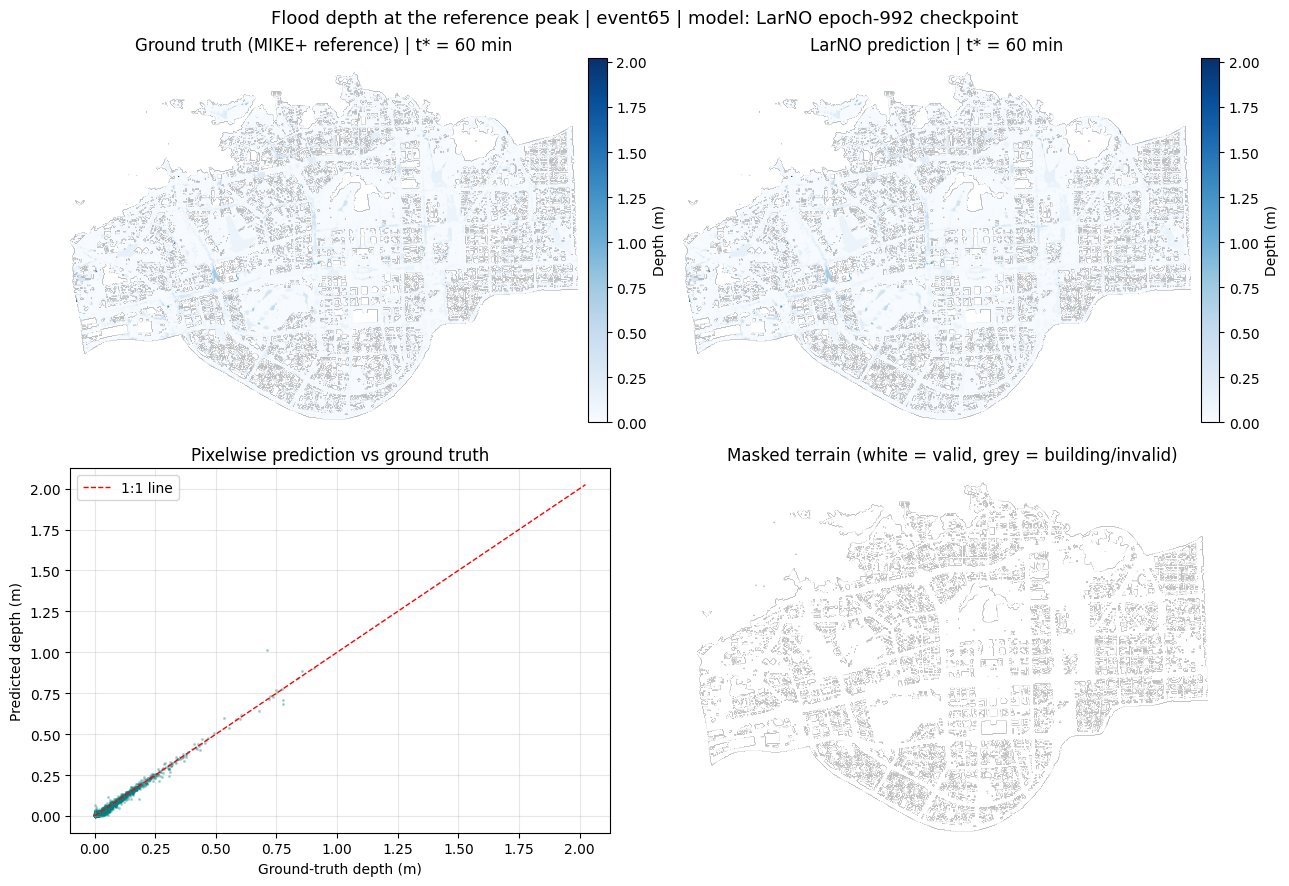

In [13]:
# Figure 4 - Flood-depth maps at the peak timestep: prediction vs ground truth (MIKE+)
pred_t = pred_depth[:, :, t_star]
gt_t   = gt_hwt[:, :, t_star]
vmax_d = float(max(gt_t.max(), pred_t.max()))
vmin_d = 0.0

fig, axes = plt.subplots(2, 2, figsize=(13, 9), gridspec_kw={"width_ratios": [1, 1]})
im0 = axes[0, 0].imshow(masked_depth(gt_t), cmap="Blues", vmin=vmin_d, vmax=vmax_d)
axes[0, 0].set_title(f"Ground truth (MIKE+ reference) | t* = {t_star*5} min")
axes[0, 0].axis("off")
fig.colorbar(im0, ax=axes[0, 0], fraction=0.04, pad=0.02, label="Depth (m)")

im1 = axes[0, 1].imshow(masked_depth(pred_t, floor_at_zero=True), cmap="Blues", vmin=vmin_d, vmax=vmax_d)
axes[0, 1].set_title(f"LarNO prediction | t* = {t_star*5} min")
axes[0, 1].axis("off")
fig.colorbar(im1, ax=axes[0, 1], fraction=0.04, pad=0.02, label="Depth (m)")

# Scatter of predicted vs reference depth (all pixels, subsampled for visibility)
stride = 5
g_flat = gt_t[::stride, ::stride].ravel()
p_flat = pred_t[::stride, ::stride].ravel()
keep = ~invalid_terrain[::stride, ::stride].ravel()
axes[1, 0].scatter(g_flat[keep], p_flat[keep], s=1.5, alpha=0.25, color="teal", rasterized=True)
axes[1, 0].plot([0, vmax_d], [0, vmax_d], "r--", lw=1, label="1:1 line")
axes[1, 0].set_xlabel("Ground-truth depth (m)")
axes[1, 0].set_ylabel("Predicted depth (m)")
axes[1, 0].set_title("Pixelwise prediction vs ground truth")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

axes[1, 1].imshow(np.ma.masked_array(np.zeros_like(dem), invalid_terrain), cmap="Greys", vmin=0, vmax=1)
axes[1, 1].axis("off")
axes[1, 1].set_title("Masked terrain (white = valid, grey = building/invalid)")

fig.suptitle(f"Flood depth at the reference peak | {EVENT} | model: LarNO epoch-992 checkpoint", fontsize=13)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig4_pred_vs_ground_truth_{EVENT}.png", dpi=150)
plt.show()

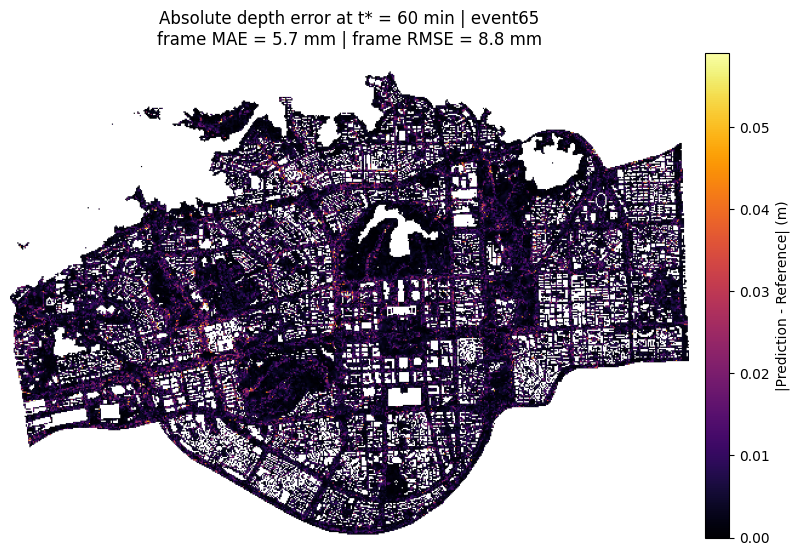

In [14]:
# Figure 5 - Absolute error map at the peak timestep
err_t = np.abs(pred_t - gt_t)
err_show = np.ma.masked_array(err_t, invalid_terrain)
ema = float(err_t[~invalid_terrain].mean())
ermse = float(np.sqrt((err_t[~invalid_terrain] ** 2).mean()))

fig, ax = plt.subplots(figsize=(9, 5.6))
im = ax.imshow(err_show, cmap="inferno", vmin=0, vmax=max(0.05, float(np.percentile(err_t[~invalid_terrain], 99.9))))
ax.set_title(f"Absolute depth error at t* = {t_star*5} min | {EVENT}\n"
             f"frame MAE = {ema*1000:.1f} mm | frame RMSE = {ermse*1000:.1f} mm")
ax.axis("off")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="|Prediction - Reference| (m)")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig5_absolute_error_map_{EVENT}.png", dpi=150)
plt.show()

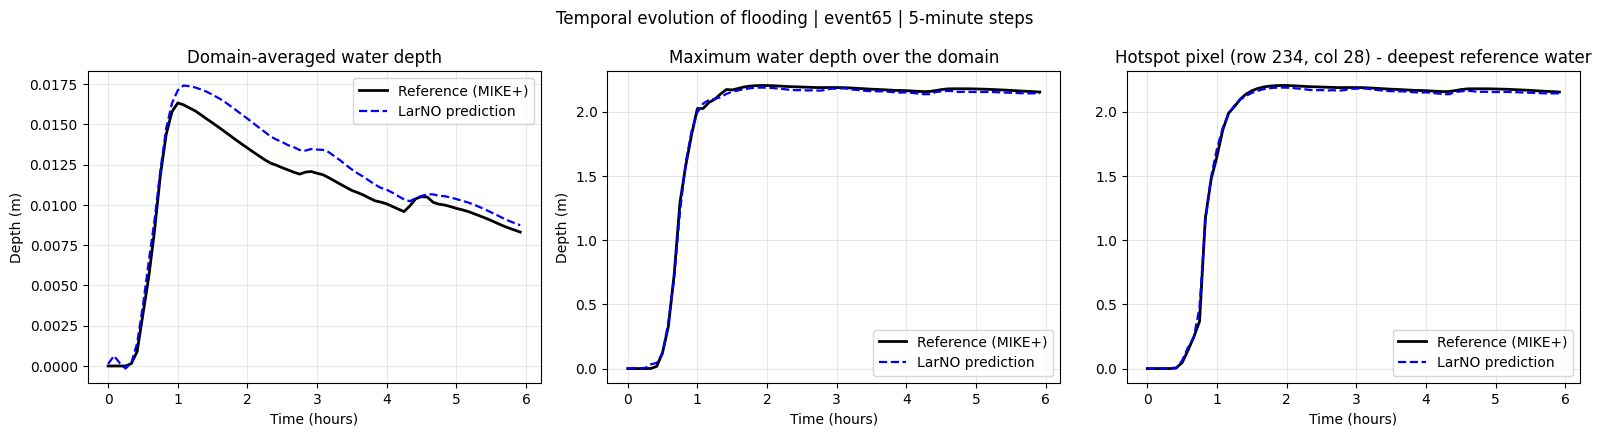

In [15]:
# Figure 6 - Time series: domain statistics and the deepest hotspot pixel
mean_gt   = gt_hwt.mean(axis=(0, 1))
mean_pred = pred_depth.mean(axis=(0, 1))
max_gt    = gt_hwt.max(axis=(0, 1))
max_pred  = pred_depth.max(axis=(0, 1))

iy, ix = np.unravel_index(np.argmax(gt_hwt.max(axis=-1)), (H, W))   # pixel with deepest GT water
pixel_gt   = gt_hwt[iy, ix, :]
pixel_pred = pred_depth[iy, ix, :]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
axes[0].plot(time_hours, mean_gt,   "k-",  lw=2,   label="Reference (MIKE+)")
axes[0].plot(time_hours, mean_pred, "b--", lw=1.6, label="LarNO prediction")
axes[0].set_title("Domain-averaged water depth")
axes[0].set_ylabel("Depth (m)")

axes[1].plot(time_hours, max_gt,   "k-",  lw=2,   label="Reference (MIKE+)")
axes[1].plot(time_hours, max_pred, "b--", lw=1.6, label="LarNO prediction")
axes[1].set_title("Maximum water depth over the domain")
axes[1].set_ylabel("Depth (m)")

axes[2].plot(time_hours, pixel_gt,   "k-",  lw=2,   label="Reference (MIKE+)")
axes[2].plot(time_hours, pixel_pred, "b--", lw=1.6, label="LarNO prediction")
axes[2].set_title(f"Hotspot pixel (row {iy}, col {ix}) - deepest reference water")

for ax in axes:
    ax.set_xlabel("Time (hours)")
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle(f"Temporal evolution of flooding | {EVENT} | 5-minute steps", fontsize=12)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig6_timeseries_{EVENT}.png", dpi=150)
plt.show()

Official animated comparison (reference (left) vs LarNO (right)):
/content/LarNO/exp/20260220_183648_006352/visualization/region1_20m/epoch_992/event65_epoch992.gif (0.5 MB)


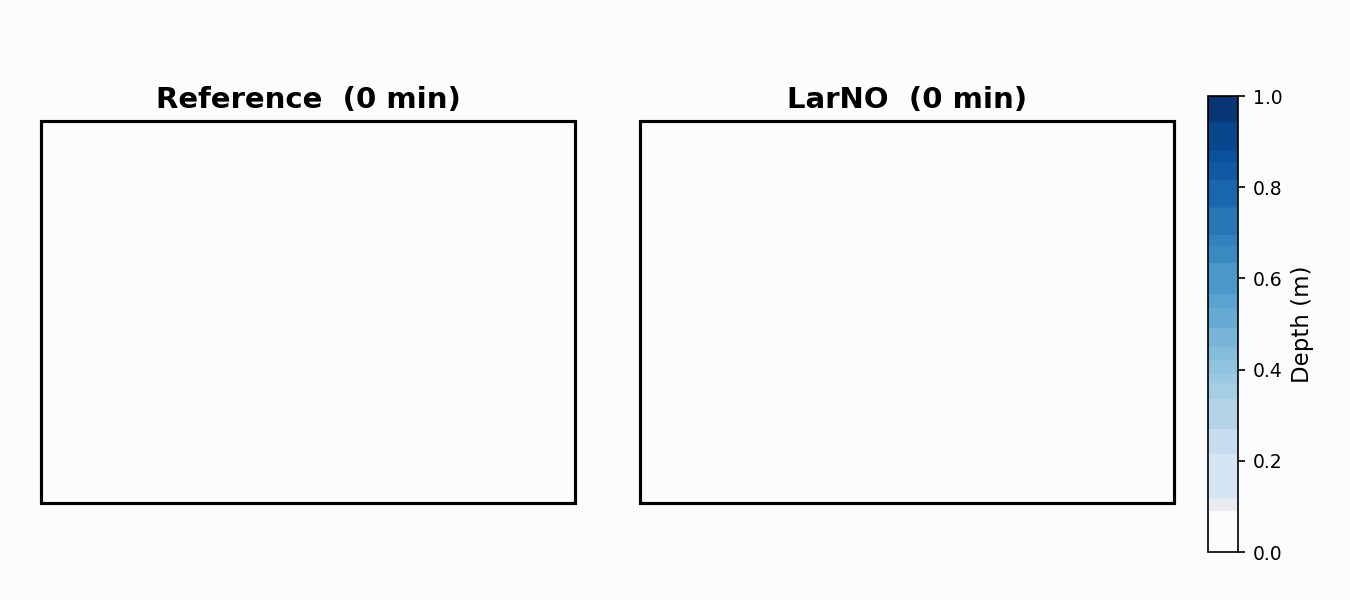

In [16]:
# Figure 7 - Animation: official side-by-side GIF produced by the official pipeline
# (every event also has an equivalent GIF; we display the first one inline)
from IPython.display import Image as IPyImage, display

if VIS_GIFS:
    gif_for_event = [g for g in VIS_GIFS if EVENT in os.path.basename(g)]
    gif_path = gif_for_event[0] if gif_for_event else VIS_GIFS[0]
    print(f"Official animated comparison ({'reference (left)'} vs {'LarNO (right)'}):")
    print(gif_path, f"({os.path.getsize(gif_path)/1e6:.1f} MB)")
    display(IPyImage(filename=gif_path))
else:
    print("No official GIF found - skipped (map animations require >= 1 event).")

---
# Section H — Evaluation Metrics (official implementation)

The official `test.py` writes per-event metrics to an Excel file. Reported metrics:

| Metric | Meaning in simple terms | Better when |
|---|---|---|
| **MAE** | average absolute depth error (m) | lower |
| **MSE** | average squared depth error (m²) — penalizes large errors more | lower |
| **RMSE** | square root of MSE, same units as depth (m) | lower |
| **R²** | fraction of depth variance explained over all pixels/time (1 = perfect) | higher |
| **PeakR²** | R² evaluated on the single frame where the *reference* flood peaks — the moment that matters most for risk | higher |
| **CSI** | Critical Success Index for the flooded/not-flooded footprint (`depth > 3 cm` at any time) | higher |

We then **independently recompute all six metrics** from the saved prediction arrays and the ground-truth
arrays, using the same formulas as the official trainer — and compare. They must agree.

In [17]:
# Official metrics table (written by the official pipeline)
import pandas as pd
from IPython.display import display

metrics_df = pd.read_excel(METRICS_XLSX[-1])
print(f"Official metrics file: {METRICS_XLSX[-1]}")
display(metrics_df)

Official metrics file: /content/LarNO/exp/20260220_183648_006352/test_metrics/region1_20m/metrics_epoch_992_n@2.xlsx


,Event,R2,MSE,RMSE,MAE,PeakR2,CSI
0,event65,0.993608,0.000017,0.004119,0.001988,0.986346,0.846333
1,event66,0.993779,0.000017,0.004162,0.002035,0.986853,0.852405
2,Overall (mean±std),0.993693±0.000086,0.000017±0.000000,0.004140±0.000021,0.002012±0.000024,0.986599±0.000253,0.849369±0.003036


In [18]:
# Independent verification: recompute metrics from saved arrays with the official formulas
import numpy as np, os

def compute_metrics(y_true, y_pred, flood_thr=0.03):
    '''Same formulas as neuralop/training/trainer.py evaluate_for_test (units: metres).'''
    eps = 1e-12
    diff = y_pred - y_true
    mse  = float(np.mean(diff ** 2))
    rmse = float(np.sqrt(mse + eps))
    mae  = float(np.mean(np.abs(diff)))
    ss_res = float(np.sum(diff ** 2))
    ss_tot = float(np.sum((y_true - y_true.mean()) ** 2))
    r2 = float(1.0 - ss_res / (ss_tot + eps))
    t_star_local = int(np.argmax(y_true.mean(axis=(0, 1))))
    tp_, gp_ = y_true[..., t_star_local].ravel(), y_pred[..., t_star_local].ravel()
    ss_res_p = float(np.sum((gp_ - tp_) ** 2))
    ss_tot_p = float(np.sum((tp_ - tp_.mean()) ** 2))
    peak_r2 = float(1.0 - ss_res_p / (ss_tot_p + eps))
    true_flood = y_true.max(axis=-1) > flood_thr
    pred_flood = y_pred.max(axis=-1) > flood_thr
    tp = np.sum(true_flood & pred_flood)
    fp = np.sum(~true_flood & pred_flood)
    fn = np.sum(true_flood & ~pred_flood)
    csi = float(tp / (tp + fp + fn + eps))
    return {"R2": r2, "MSE": mse, "RMSE": rmse, "MAE": mae, "PeakR2": peak_r2, "CSI": csi}

rows = []
for ev in CHOSEN_EVENTS:
    gt = np.transpose(np.load(f"{DATA_ROOT}/flood/region1_20m/{ev}/h.npy"), (1, 2, 0))  # metres, (H,W,T)
    pr = np.load([p for p in PRED_NPYS if ev in os.path.basename(p)][0])                 # metres, (H,W,T)
    assert gt.shape == pr.shape, f"Shape mismatch for {ev}: {gt.shape} vs {pr.shape}"
    mine = compute_metrics(gt, pr)
    official = metrics_df.loc[metrics_df["Event"] == ev].iloc[0]
    row = {"Event": ev}
    for k in ["R2", "MSE", "RMSE", "MAE", "PeakR2", "CSI"]:
        row[f"{k} (independent)"] = mine[k]
        row[f"{k} (official xlsx)"] = float(official[k])
        row[f"{k} OK"] = abs(mine[k] - float(official[k])) < 1e-4
    rows.append(row)

check_df = pd.DataFrame(rows)
all_ok = all(v for col in check_df.columns if col.endswith(" OK") for v in check_df[col])
print(check_df.to_string(index=False))
print()
print("[ok] Independent recomputation matches the official metrics (tolerance 1e-4)." if all_ok
      else "[FAIL] Independent recomputation did NOT match - investigate before trusting results.")
assert all_ok, 'Metric verification failed.'

  Event  R2 (independent)  R2 (official xlsx)  R2 OK  MSE (independent)  MSE (official xlsx)  MSE OK  RMSE (independent)  RMSE (official xlsx)  RMSE OK  MAE (independent)  MAE (official xlsx)  MAE OK  PeakR2 (independent)  PeakR2 (official xlsx)  PeakR2 OK  CSI (independent)  CSI (official xlsx)  CSI OK
event65          0.993608            0.993608   True           0.000017             0.000017    True            0.004119              0.004119     True           0.001988             0.001988    True              0.986346                0.986346       True           0.846333             0.846333    True
event66          0.993779            0.993779   True           0.000017             0.000017    True            0.004162              0.004162     True           0.002035             0.002035    True              0.986853                0.986853       True           0.852405             0.852405    True

[ok] Independent recomputation matches the official metrics (tolerance 1e-4).


---
# Section I — Results Summary Report

Generates `report.md` from the values actually produced in this run (no hardcoded numbers):
checkpoint identity, dataset events, runtime/hardware, the official metrics table, observations and limitations.

In [19]:
import os, platform, datetime
import numpy as np, pandas as pd

REPORT_PATH = f"{PROJECT_DIR}/results/report.md"
os.makedirs(os.path.dirname(REPORT_PATH), exist_ok=True)

run_ts = datetime.datetime.now().strftime("%Y-%m-%d %H:%M")
mean_row = metrics_df.iloc[-1].to_dict()

def overall(m):
    '''Parse the overall mean from the official "mean±std" string cell.'''
    return float(str(mean_row[m]).split(chr(177))[0])

# A few factual observations computed from the arrays
gt_mean_peak = float(np.max(np.transpose(np.load(f'{DATA_ROOT}/flood/region1_20m/{CHOSEN_EVENTS[0]}/h.npy'), (1,2,0)).mean(axis=(0,1))))
flooded_frac = float((np.transpose(np.load(f'{DATA_ROOT}/flood/region1_20m/{CHOSEN_EVENTS[0]}/h.npy'), (1,2,0)).max(axis=-1) > 0.03).mean())
pred_min_all = min(float(np.load(p).min()) for p in PRED_NPYS)

def fmt_metrics_table(df):
    cols = ["Event", "R2", "MSE", "RMSE", "MAE", "PeakR2", "CSI"]
    def cellval(v):
        try:
            return f"{float(v):.6g}"
        except (TypeError, ValueError):
            return str(v)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df[cols].iterrows():
        vals = [str(r["Event"])] + [cellval(r[c]) for c in cols[1:]]
        lines.append("| " + " | ".join(vals) + " |")
    return "\n".join(lines)

report = f'''# FloodGuard AI - Results Summary

_Generated automatically by the notebook on {run_ts}. Research prototype - not an operational forecast system._

## Run identity
- **Model**: LarNO (Latent Autoregressive Neural Operator), official pretrained checkpoint
- **Checkpoint**: `{CKPT_NAME}` (epoch 992), experiment `{EXP_ID}`
- **Model source**: https://huggingface.co/holmescao/LarNO (exp_weights.zip)
- **Code**: official repository https://github.com/holmescao/LarNO, entry point `test.py`
- **Dataset**: LarNO benchmark, Futian district Shenzhen, `region1_20m` (20 m / 5 min, 6 h events)
- **Evaluated events**: {', '.join(CHOSEN_EVENTS)} (official test split, subset)
- **Ground truth**: MIKE+ hydrodynamic simulations (not field observations)

## Hardware & runtime
- **Environment**: Google Colab = {IS_COLAB} | {platform.system()} | Python {platform.python_version()}
- **Device**: {'GPU: ' + torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU only'}
- **Official inference wall time (all evaluated events)**: {elapsed:.1f} s
- **Determinism**: eval mode, fixed event order, no dropout; predictions are deterministic

## Evaluation metrics (official implementation, verified by independent recomputation)
{fmt_metrics_table(metrics_df)}

- Metrics are computed by the official `test.py` on all 72 timesteps x 400 x 560 cells, in metres.
- Independent recomputation from the saved arrays matched the official values within 1e-4 (see Section H).

## Observations from the visualizations
- The rainfall event totals {rain_total_mm:.1f} mm (domain mean); reference flooding is spatially concentrated.
- Maximum reference depth for {CHOSEN_EVENTS[0]}: {gt_hwt.max():.2f} m; flooded footprint (depth > 3 cm at any time): {flooded_frac*100:.2f}% of cells.
- LarNO reproduces the flood footprint well (CSI ≈ {overall('CSI'):.2f}) and the peak frame (PeakR² ≈ {overall('PeakR2'):.3f}).
- The model output is not constrained to be non-negative (observed minimum across predictions: {pred_min_all:.4f} m), a known characteristic of the official model; map displays floor values at 0.

## Known limitations & error sources
- Ground truth is a **simulated** reference (MIKE+), not observed flooding; the confidential drainage network is not an input.
- Released data is a 20 m downsample of the paper's 5 m experiments - metrics differ from the paper's headline numbers.
- Rare extreme events, sensor/forcing errors and unmodelled infrastructure outfalls are not represented.
- **These numbers describe the Shenzhen benchmark only and are not evidence of predictive accuracy in Egypt or anywhere else.**

## Egypt disclaimer
No LarNO prediction for Egypt is produced anywhere in this notebook. See `Egypt_data_readiness_checklist.md`
(Part 2) for the required data and validation steps before any Egypt experiment could be scientifically defensible.
'''

with open(REPORT_PATH, "w") as f:
    f.write(report)
print(f"Report written: {REPORT_PATH} ({os.path.getsize(REPORT_PATH)} bytes)")
print("\n" + "=" * 70 + "\n")
print(report[:3000])
if len(report) > 3000:
    print("... [see report.md for the full text]")

Report written: /content/FloodGuard_AI/results/report.md (3025 bytes)


# FloodGuard AI - Results Summary

_Generated automatically by the notebook on 2026-10-15 20:30. Research prototype - not an operational forecast system._

## Run identity
- **Model**: LarNO (Latent Autoregressive Neural Operator), official pretrained checkpoint
- **Checkpoint**: `model_epoch_992_error@0.000055821` (epoch 992), experiment `20260220_183648_006352`
- **Model source**: https://huggingface.co/holmescao/LarNO (exp_weights.zip)
- **Code**: official repository https://github.com/holmescao/LarNO, entry point `test.py`
- **Dataset**: LarNO benchmark, Futian district Shenzhen, `region1_20m` (20 m / 5 min, 6 h events)
- **Evaluated events**: event65, event66 (official test split, subset)
- **Ground truth**: MIKE+ hydrodynamic simulations (not field observations)

## Hardware & runtime
- **Environment**: Google Colab = True | Linux | Python 3.13.15
- **Device**: GPU: Tesla T4
- **Official inference wall time (

---
# Section J — Save & Download Results

Collects everything produced into `/content/FloodGuard_AI/results`, packages it as
**`FloodGuard_AI_Results.zip`**, verifies the archive is non-empty, and offers a download link (Colab).

Google Drive is **not required**; an optional Drive-mount cell is provided at the end and is disabled by default.

In [20]:
# Collect official outputs + our figures/logs/report into results/, then zip
import os, glob, shutil, zipfile

RESULTS_DIR = f"{PROJECT_DIR}/results"
ZIP_PATH    = f"{PROJECT_DIR}/FloodGuard_AI_Results.zip"
INCLUDE_PREDICTIONS = True   # prediction .npy files are the largest items (~65 MB per event)

os.makedirs(RESULTS_DIR, exist_ok=True)

def copy_tree(dst, pattern_root, subdir):
    src = os.path.join(pattern_root, subdir)
    if os.path.isdir(src):
        shutil.copytree(src, os.path.join(dst, os.path.basename(subdir)), dirs_exist_ok=True)

# Official pipeline outputs
copy_tree(RESULTS_DIR, OUT_DIR, "test_metrics")
copy_tree(RESULTS_DIR, OUT_DIR, "visualization")
if INCLUDE_PREDICTIONS:
    copy_tree(RESULTS_DIR, OUT_DIR, "pred_results")

# Environment snapshot
with open(f"{RESULTS_DIR}/environment_report.txt", "w") as f:
    f.write(f"python {platform.python_version()} | torch {torch.__version__} | cuda {torch.version.cuda}\n")
    f.write(f"gpu {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'}\n")
    f.write(f"model repo holmescao/LarNO | dataset holmescao/LarNO-dataset\n")
    f.write(f"checkpoint {CKPT_NAME} | events {CHOSEN_EVENTS}\n")
    import importlib.metadata as md
    for pkg in ["neuraloperator", "torch-harmonics", "tensorly", "tensorly-torch", "numpy", "pandas"]:
        try:
            f.write(f"{pkg} {md.version(pkg)}\n")
        except Exception:
            pass

# Build the ZIP
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, dirs, files in os.walk(RESULTS_DIR):
        for fn in files:
            full = os.path.join(root, fn)
            zf.write(full, os.path.relpath(full, PROJECT_DIR))

assert os.path.exists(ZIP_PATH) and os.path.getsize(ZIP_PATH) > 0, "ZIP archive is missing or empty."
with zipfile.ZipFile(ZIP_PATH) as zf:
    names = zf.namelist()
    bad = zf.testzip()
assert bad is None, f"Corrupt entry in ZIP: {bad}"

print(f"Archive : {ZIP_PATH}")
print(f"Size    : {os.path.getsize(ZIP_PATH)/1e6:.1f} MB | entries: {len(names)}")
print("Contents (top level):")
for n in sorted(set([n.split('/')[0] + ('/' if '/' in n else '') for n in names])):
    print("  ", n)

Archive : /content/FloodGuard_AI/FloodGuard_AI_Results.zip
Size    : 120.8 MB | entries: 21
Contents (top level):
   results/


In [21]:
# Download the ZIP (Colab). If the automatic download is unavailable, use the Colab file browser.
AUTO_DOWNLOAD = True

if IS_COLAB and AUTO_DOWNLOAD:
    try:
        from google.colab import files
        files.download(ZIP_PATH)
    except Exception as e:
        print("Automatic browser download unavailable here:", repr(e))
        print("Download manually from the Colab file browser (left panel):", ZIP_PATH)
else:
    print("Not running in Colab, or AUTO_DOWNLOAD disabled.")
    print("The archive is at:", ZIP_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
# OPTIONAL: Google Drive backup (disabled by default - the notebook works fully without it)
USE_GOOGLE_DRIVE = False

if USE_GOOGLE_DRIVE:
    if not IS_COLAB:
        print("Not running in Colab - skipping Drive mount.")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        drive_dir = "/content/drive/MyDrive/FloodGuard_AI"
        os.makedirs(drive_dir, exist_ok=True)
        shutil.copy2(ZIP_PATH, os.path.join(drive_dir, os.path.basename(ZIP_PATH)))
        print("Backed up to:", os.path.join(drive_dir, os.path.basename(ZIP_PATH)))
else:
    print("Google Drive backup disabled (set USE_GOOGLE_DRIVE = True to enable).")

Google Drive backup disabled (set USE_GOOGLE_DRIVE = True to enable).


---
# Part 2 — Egypt Adaptation Research (no Egyptian predictions)

**This part contains no model predictions for Egypt.** The pretrained checkpoint was trained on the
Futian/Shenzhen (China) urban benchmark; running it on Egyptian terrain and calling the output an
"Egyptian flood forecast" would be scientifically invalid. This part documents what a defensible
adaptation would require.

## 2.1 — Why we do not run LarNO on Egypt today

| Gap | LarNO (Futian checkpoint) | Egypt need |
|---|---|---|
| Climate hydrology | humid subtropical, frequent rainfall | hyper-arid with rare flash floods (Sinai, Red Sea coast) |
| Urban form | dense Chinese megacity, engineered drainage | different street/plot morphology; wadi channels dominate |
| Terrain data | 20 m DEM consistent with MIKE+ model | requires hydrologically conditioned DEM (e.g. Copernicus GLO-30 / ALOS AW3D30) with wadi networks resolved |
| Rainfall forcing | local rain-gauge/radar-driven fields at 20 m | IMERG at 0.1° (~10 km) must be downscaled to the model grid - a major source of uncertainty |
| Reference labels | MIKE+ hydraulic simulations | none published; would need calibrated hydraulic modelling or validated observations |
| Drainage data | confidential for Futian | unavailable for Egyptian cities too |

Zero-shot transfer is a research hypothesis for this model (the paper demonstrates few-shot fine-tuning
on a *different Chinese* catchment, not cross-climate transfer), so it must be tested, not assumed.

## 2.2 — NASA GPM IMERG as a candidate rainfall source (verified facts)

Verified against the official NASA GPM data directory (gpm.nasa.gov/data/directory):

| Product | Latency | Spatial resolution | Temporal resolution | Suggested use |
|---|---|---|---|---|
| IMERG **Early** (V07B) | ~4 hours | 0.1 deg (~10 km) | 30 min | near-real-time monitoring experiments |
| IMERG **Late** (V07B) | ~12 hours | 0.1 deg | 30 min | better interpolated estimates, still NRT |
| IMERG **Final** (V07) | ~3.5 months | 0.1 deg | 30 min (plus daily/monthly) | research-grade, gauge-adjusted - use for retraining/validation |

Access: NASA GES DISC (`GPM_3IMERGHHE_07`, `GPM_3IMERGHHL_07`, `GPM_3IMERGHH_07`), and the PPS
near-real-time HTTPS/FTPS servers. IMERG provides a precipitation **rate** (mm/hr) or accumulation
depending on product; any LarNO-style pipeline needs it converted to mm per model timestep
(e.g. mm/5-min = rate_mm_per_hour x 5/60) *and* spatially downscaled from ~10 km to the terrain grid.

## 2.3 — Data-readiness checklist for a future Egypt experiment

A defensible Egypt study would require, in order:

1. **Terrain** - hydrologically conditioned DEM for the wadi/city (e.g. Copernicus GLO-30 or ALOS AW3D30), 
   reviewed for artifacts and aligned to the exact model grid; buildings/walls handled as in this benchmark.
2. **Rainfall forcing** - historical storm events from IMERG Final (with gauge/radar cross-checks where they exist),
   downscaled to the target grid; documented assumptions and sensitivity tests.
3. **Catchment & infrastructure** - wadi channel networks, culverts, dams, and any drainage data obtainable;
   where confidential/absent, document the omission explicitly.
4. **Reference labels** - calibrated hydrodynamic simulations (like MIKE+, HEC-RAS, LISFLOOD-FP) or
   independently validated observations of real flood events for the exact study area.
5. **Model adaptation** - fine-tune or retrain (the paper supports few-shot fine-tuning); learning from
   scratch with limited data is a research question in itself.
6. **Independent validation** - hold out real events; report the same metrics (MAE, RMSE, R2, PeakR2, CSI)
   and compare against a simple baseline (e.g. rainfall accumulation thresholding).
7. **Governance** - coordinate with Egyptian authorities (e.g. NRIAG/MWRI relevant departments) before any
   operational use; no emergency-alert claims from a research prototype.

Until steps 1-4 exist, the honest deliverable is this checklist - **not** numeric risk scores for Egypt.

In [23]:
# Write the Egypt data-readiness checklist into the results and add it to the archive
checklist = '''# Egypt Data-Readiness Checklist (FloodGuard AI - research only)

STATUS: data-readiness planning document. No Egyptian predictions were produced.

Study areas of interest: Sinai wadis, Red Sea Governorate coastal catchments.

Required before any Egypt experiment can be scientifically defensible:

[ ] 1. Hydrologically conditioned DEM (e.g. Copernicus GLO-30, ALOS AW3D30) on the model grid
[ ] 2. Historical storm catalog from NASA GPM IMERG Final (0.1 deg, 30 min, ~3.5-month latency),
      downscaled to the grid; Early/Late runs (4 h / 12 h latency) only for near-real-time experiments
[ ] 3. Wadi/channel network + infrastructure (culverts, dams); confidential gaps documented
[ ] 4. Reference water-depth labels: calibrated hydrodynamic simulations or validated observations
[ ] 5. Adaptation plan: few-shot fine-tuning of the released checkpoint (paper-supported) with documented splits
[ ] 6. Independent validation on held-out real events + baseline comparison
[ ] 7. Institutional coordination before any operational or public-facing use

Do NOT interpret LarNO benchmark performance (Shenzhen) as predictive skill in Egypt.
'''
checklist_path = os.path.join(RESULTS_DIR, "Egypt_data_readiness_checklist.md")
with open(checklist_path, "w") as f:
    f.write(checklist)
print("Checklist written:", checklist_path)

# Add the checklist to the results archive (append + verify)
with zipfile.ZipFile(ZIP_PATH, "a", zipfile.ZIP_DEFLATED) as zf:
    zf.write(checklist_path, "Egypt_data_readiness_checklist.md")
with zipfile.ZipFile(ZIP_PATH) as zf:
    assert "Egypt_data_readiness_checklist.md" in zf.namelist()
    assert zf.testzip() is None
print(f"[ok] Checklist added to {ZIP_PATH} ({os.path.getsize(ZIP_PATH)/1e6:.1f} MB total)")

Checklist written: /content/FloodGuard_AI/results/Egypt_data_readiness_checklist.md


[ok] Checklist added to /content/FloodGuard_AI/FloodGuard_AI_Results.zip (120.8 MB total)


---
## Citation

If you use LarNO, the benchmark dataset, or this workflow in research, cite:

```bibtex
@article{cao2026large,
  title={Large-scale urban flood modeling and zero-shot high-resolution generalization with LarNO},
  author={Cao, Xiaoyan and Yao, Yao and Wang, Zhi and Zhao, Zhangxinyue and Borthwick, Alistair GL and Qin, Huapeng},
  journal={Journal of Hydrology},
  pages={135686},
  year={2026},
  doi={10.1016/j.jhydrol.2026.135686},
  publisher={Elsevier}
}
```

Benchmark dataset citation (figshare DOI: 10.6084/m9.figshare.30529031.v4) - see the repository tutorials.
NASA GPM IMERG data: acknowledge NASA GPM / GES DISC per https://gpm.nasa.gov/data/policy.

In [24]:
# FloodGuard AI - Self-Test
# Standalone integrity check of this run; safe to execute alone (does not depend on earlier cells).
import os, glob, re, sys
import numpy as np

PASS, FAIL = [], []
def check(name, fn):
    try:
        info = fn()
        PASS.append(name)
        print(f"[PASS] {name}" + (f" - {info}" if info else ""))
    except Exception as e:
        FAIL.append(name)
        print(f"[FAIL] {name} - {type(e).__name__}: {e}")

LARNO_DIR = "/content/LarNO"
PKG_DIR   = f"{LARNO_DIR}/code/urbanflood_larfno"
DATA_ROOT = f"{LARNO_DIR}/benchmark/urbanflood"
EXP_ROOT  = f"{LARNO_DIR}/exp"

def t_repo():
    assert os.path.isfile(f"{PKG_DIR}/test.py"), "official test.py missing"
    return "official repository present"
check("Official LarNO repository", t_repo)

def t_import():
    sys.path.insert(0, PKG_DIR)
    import torch
    from neuralop import get_model  # noqa: F401
    dev = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
    return f"neuralop import OK | torch {torch.__version__} | device: {dev}"
check("Package import & PyTorch", t_import)

def t_checkpoint():
    ckpts = glob.glob(f"{EXP_ROOT}/**/*_state_dict.pt", recursive=True)
    assert ckpts, "no *_state_dict.pt found"
    ckpt = max(ckpts, key=lambda p: int(re.search(r"epoch_(\d+)", p).group(1)))
    assert os.path.getsize(ckpt) > 1e6, "checkpoint suspiciously small"
    import torch
    sd = torch.load(ckpt, map_location="cpu")
    n = sum(v.numel() for v in sd.values())
    return f"{os.path.basename(ckpt)} | {len(sd)} tensors | {n/1e6:.1f} M params"
check("Pretrained checkpoint", t_checkpoint)

def t_data():
    dem = np.load(f"{DATA_ROOT}/geodata/region1_20m/dem.npy")
    assert dem.shape == (400, 560), f"unexpected DEM shape {dem.shape}"
    evs = sorted(glob.glob(f"{DATA_ROOT}/flood/region1_20m/event*"))
    assert evs, "no events downloaded"
    rain = np.load(f"{evs[0]}/rainfall.npy")
    h = np.load(f"{evs[0]}/h.npy")
    assert rain.shape == h.shape == (72, 400, 560), "unexpected event shapes"
    assert np.isfinite(rain).all() and np.isfinite(h).all(), "non-finite values in event data"
    return f"DEM {dem.shape} | {len(evs)} event(s) | {os.path.basename(evs[0])} {rain.shape}"
check("Benchmark data (Futian region1_20m)", t_data)

def t_official_outputs():
    xlsx = glob.glob(f"{EXP_ROOT}/*/test_metrics/region1_20m/*.xlsx")
    npys = glob.glob(f"{EXP_ROOT}/*/pred_results/region1_20m/**/*.npy", recursive=True)
    gifs = glob.glob(f"{EXP_ROOT}/*/visualization/region1_20m/**/*.gif", recursive=True)
    assert xlsx and npys and gifs, "official outputs incomplete"
    pred = np.load(sorted(npys)[0])
    assert pred.shape == (400, 560, 72) and np.isfinite(pred).all()
    return f"{len(xlsx)} metrics xlsx | {len(npys)} npy {pred.shape} | {len(gifs)} gif"
check("Official inference outputs", t_official_outputs)

def t_metrics_consistency():
    import pandas as pd
    xlsx = sorted(glob.glob(f"{EXP_ROOT}/*/test_metrics/region1_20m/*.xlsx"))[-1]
    df = pd.read_excel(xlsx)
    ev = str(df.iloc[0]["Event"])
    h = np.transpose(np.load(f"{DATA_ROOT}/flood/region1_20m/{ev}/h.npy"), (1, 2, 0))
    preds = glob.glob(f"{EXP_ROOT}/*/pred_results/region1_20m/**/*.npy", recursive=True)
    pred = np.load([p for p in preds if ev in os.path.basename(p)][0])
    mae = float(np.abs(pred - h).mean())
    off = float(df.iloc[0]["MAE"])
    assert abs(mae - off) < 1e-4, f"MAE mismatch: recomputed {mae} vs official {off}"
    return f"{ev}: recomputed MAE {mae:.6f} m matches official {off:.6f} m"
check("Metrics consistency (independent recompute)", t_metrics_consistency)

print()
print(f"Self-test: {len(PASS)} passed, {len(FAIL)} failed")
assert not FAIL, "Self-test failures: " + ", ".join(FAIL)
print("[ok] All FloodGuard AI checks passed.")

[PASS] Official LarNO repository - official repository present
[PASS] Package import & PyTorch - neuralop import OK | torch 2.11.0+cu130 | device: Tesla T4
[PASS] Pretrained checkpoint - model_epoch_992_error@0.000055821_state_dict.pt | 72 tensors | 29.1 M params


[PASS] Benchmark data (Futian region1_20m) - DEM (400, 560) | 2 event(s) | event65 (72, 400, 560)
[PASS] Official inference outputs - 1 metrics xlsx | 2 npy (400, 560, 72) | 2 gif


[PASS] Metrics consistency (independent recompute) - event65: recomputed MAE 0.001988 m matches official 0.001988 m

Self-test: 6 passed, 0 failed
[ok] All FloodGuard AI checks passed.
